In [1]:
import pandas as pd

# Загружаем датасет
df = pd.read_excel("Dry_Bean_Dataset.xlsx")

# Смотрим размер и первые строки
print("Размер датасета:", df.shape)
display(df.head())

# Проверяем названия столбцов и типы данных
print("\nИнформация о столбцах:")
df.info()

# Проверяем пропущенные значения
print("\nПропущенные значения:")
print(df.isnull().sum())

# Смотрим количество объектов каждого класса
print("\nКоличество объектов каждого сорта:")
print(df["Class"].value_counts())

Размер датасета: (13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Информация о столбцах:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtyp

In [2]:
# Отделяем признаки от целевой переменной
X = df.drop(columns=["Class"])
y = df["Class"]

print("Размер матрицы признаков:", X.shape)
print("Размер целевой переменной:", y.shape)

print("\nНазвания классов:")
print(y.unique())

Размер матрицы признаков: (13611, 16)
Размер целевой переменной: (13611,)

Названия классов:
<StringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)

print("\nРаспределение классов в обучающей выборке:")
print(y_train.value_counts())

print("\nРаспределение классов в тестовой выборке:")
print(y_test.value_counts())

Размер обучающей выборки: (10888, 16)
Размер тестовой выборки: (2723, 16)

Распределение классов в обучающей выборке:
Class
DERMASON    2837
SIRA        2109
SEKER       1621
HOROZ       1542
CALI        1304
BARBUNYA    1057
BOMBAY       418
Name: count, dtype: int64

Распределение классов в тестовой выборке:
Class
DERMASON    709
SIRA        527
SEKER       406
HOROZ       386
CALI        326
BARBUNYA    265
BOMBAY      104
Name: count, dtype: int64


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# 1. Логистическая регрессия
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

# 2. Метод опорных векторов (SVM)
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

# 3. Дерево решений
tree_model = DecisionTreeClassifier(random_state=42)

# Обучаем модели
logistic_model.fit(X_train, y_train)
svm_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)

print("Все три модели успешно обучены!")

Все три модели успешно обучены!


In [5]:
from sklearn.metrics import accuracy_score, f1_score

# Сохраняем обученные модели в словарь
models = {
    "Логистическая регрессия": logistic_model,
    "SVM": svm_model,
    "Дерево решений": tree_model
}

# Сравниваем качество моделей
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1-score (weighted)": f1_score(
            y_test, y_pred, average="weighted"
        )
    })

# Выводим результаты в виде таблицы
comparison = pd.DataFrame(results)
display(comparison.round(4))

,Модель,Accuracy,F1-score (weighted)
0,Логистическая регрессия,0.9214,0.9216
1,SVM,0.9221,0.9222
2,Дерево решений,0.8917,0.8913


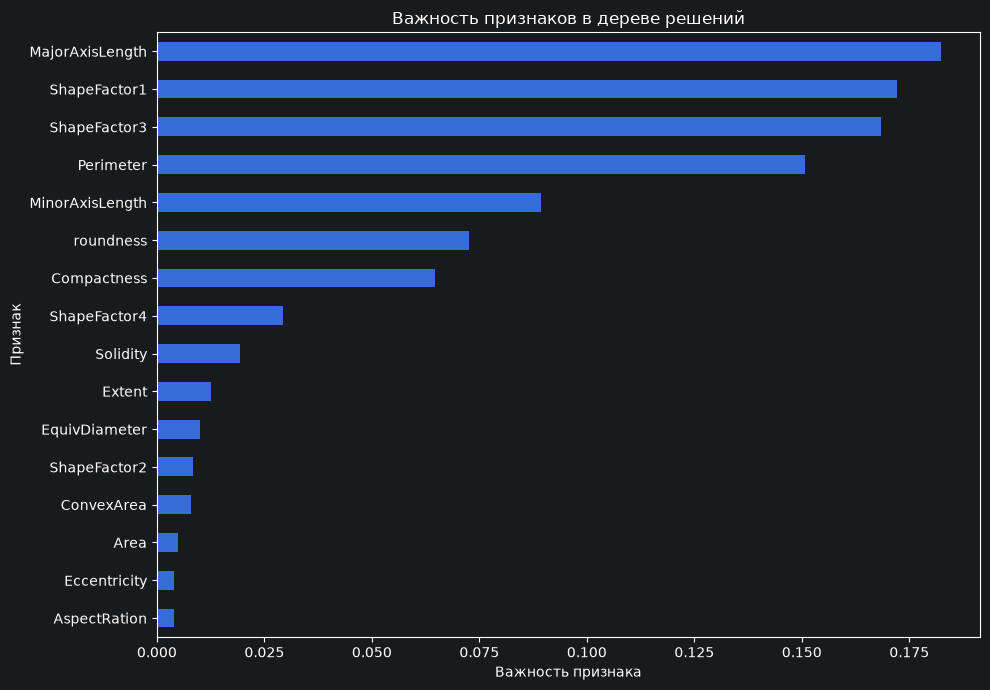

In [6]:
import matplotlib.pyplot as plt

# Получаем важность каждого признака из обученного дерева
importances = pd.Series(
    tree_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True)

# Строим горизонтальный график
plt.figure(figsize=(10, 7))
importances.plot(kind="barh")

plt.title("Важность признаков в дереве решений")
plt.xlabel("Важность признака")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

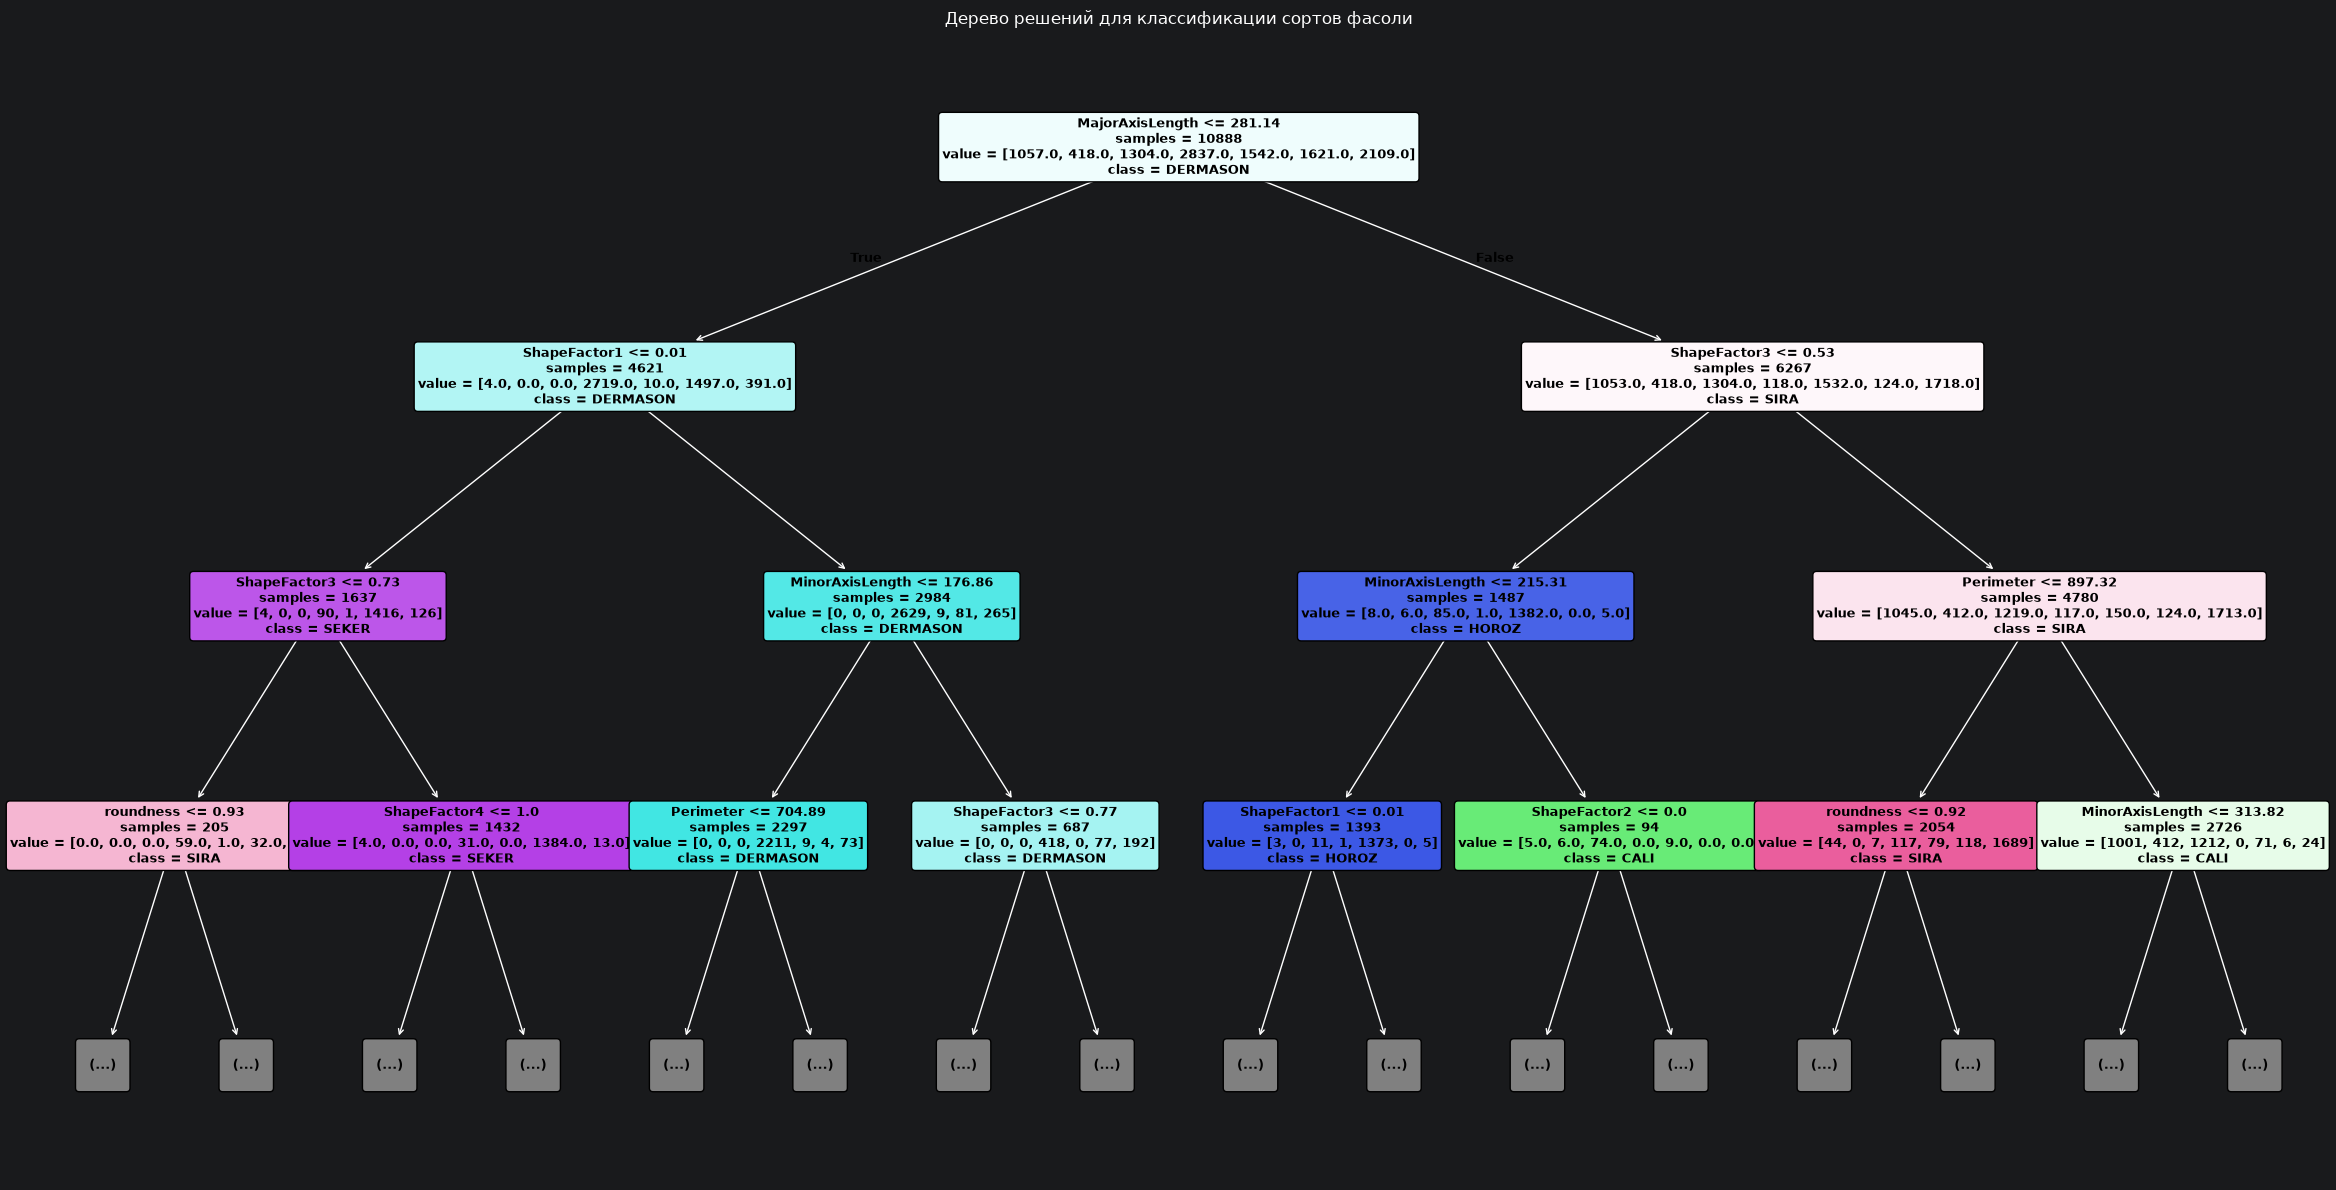

In [10]:
from sklearn.tree import plot_tree

plt.figure(figsize=(24, 12))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9,
    impurity=False,
    proportion=False,
    node_ids=False,
    precision=2,
    ax=None
)

# Делаем фон и текст узлов более контрастными
ax = plt.gca()

for text_item in ax.texts:
    text_item.set_color("black")
    text_item.set_fontweight("bold")

plt.title("Дерево решений для классификации сортов фасоли")
plt.tight_layout()
plt.show()

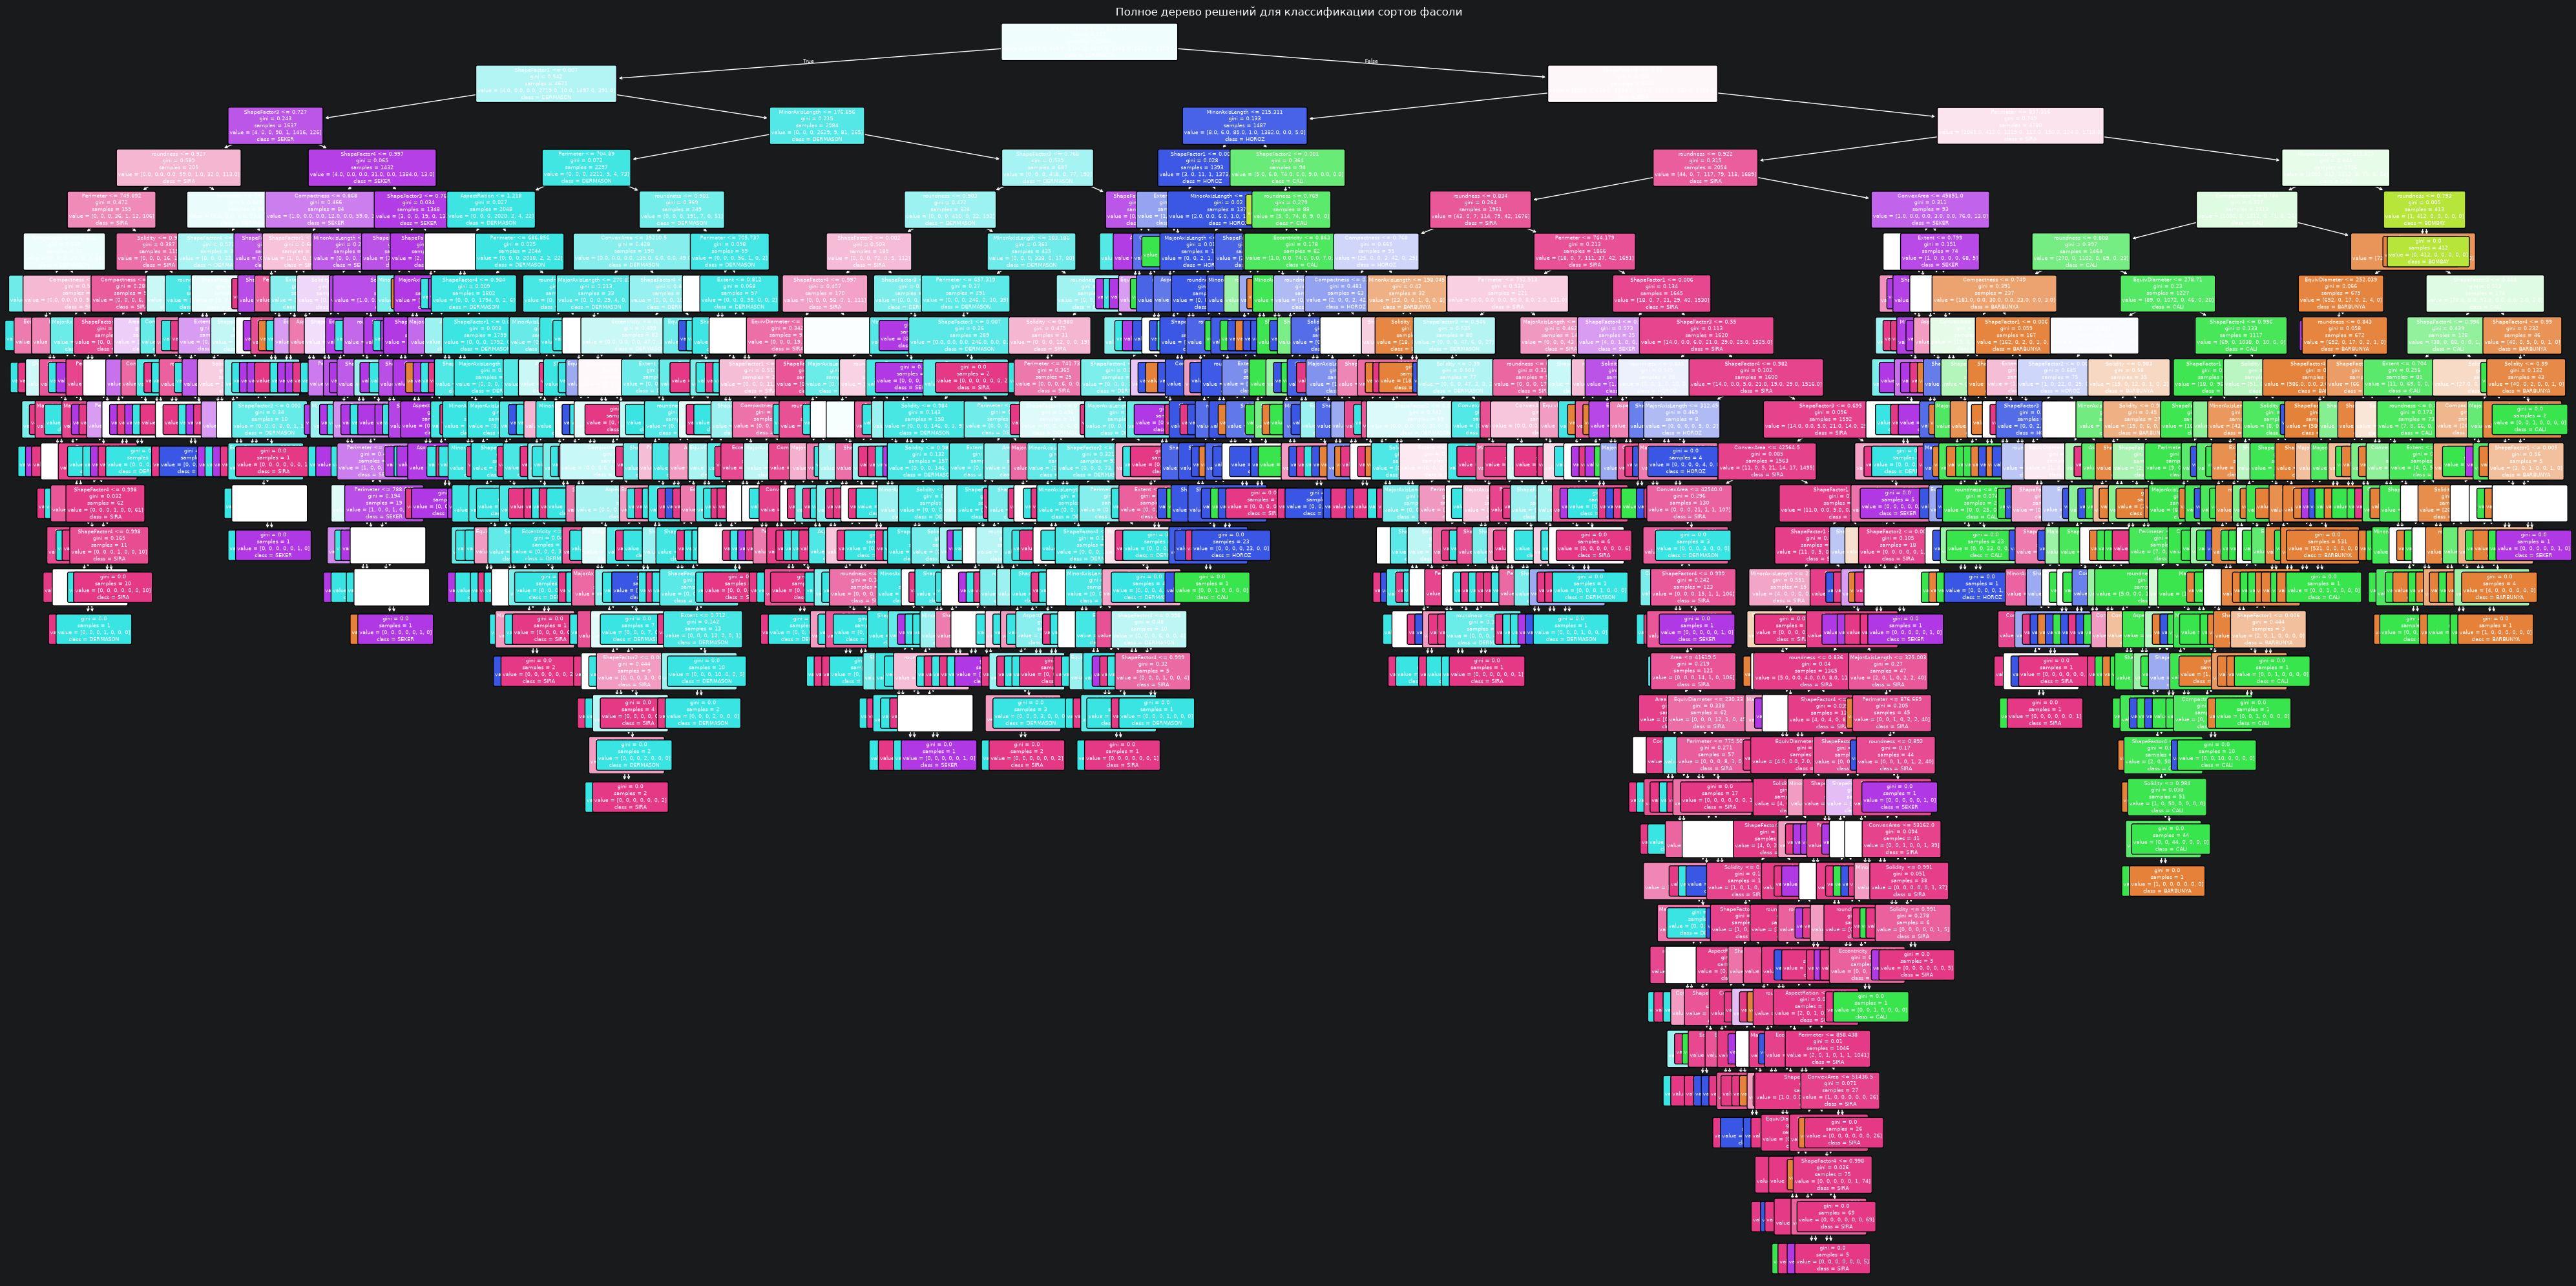

In [11]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(40, 20))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=tree_model.classes_,
    filled=True,
    rounded=True,
    fontsize=6
)

plt.title("Полное дерево решений для классификации сортов фасоли")
plt.tight_layout()
plt.show()